In [1]:

from pathlib import Path

PROJECT = Path("/home/cse-sdpl/Downloads/CMX_E3")
ORIGINAL = Path("/home/cse-sdpl/Downloads/CMX_Original")
E2 = Path("/home/cse-sdpl/Downloads/CMX_E2")

print("=" * 65)
print("E3 PROJECT VERIFICATION")
print("=" * 65)

print("E3 exists:", PROJECT.exists())
print("E2 exists:", E2.exists())
print("Original CMX exists:", ORIGINAL.exists())

print("\n--- Important files in E3 ---")

for name in [
    "train.py",
    "eval.py",
    "config",
    "configs",
    "network",
    "networks",
    "models",
    "log_TDD_mit_b2_e2",
]:
    path = PROJECT / name
    if path.exists():
        print(f"[FOUND] {path.relative_to(PROJECT)}")

print("\n--- Python source files ---")

skip = {
    ".git", "__pycache__", "datasets",
    "checkpoint", "checkpoints"
}

source_files = [
    p for p in PROJECT.rglob("*.py")
    if not any(part in skip for part in p.parts)
]

print("Total Python files:", len(source_files))

for p in source_files[:80]:
    print(p.relative_to(PROJECT))

print("\n--- E2 checkpoint ---")

checkpoint = E2 / "log_TDD_mit_b2_e2" / "checkpoint" / "epoch-100.pth"
print("Expected E2 checkpoint:", checkpoint)
print("Checkpoint exists:", checkpoint.exists())

print("\n--- E3 copied checkpoints ---")

for p in PROJECT.rglob("epoch-100.pth"):
    print(p)


E3 PROJECT VERIFICATION
E3 exists: True
E2 exists: True
Original CMX exists: True

--- Important files in E3 ---
[FOUND] train.py
[FOUND] eval.py
[FOUND] models
[FOUND] log_TDD_mit_b2_e2

--- Python source files ---
Total Python files: 842
config.py
eval.py
train.py
.venv/lib64/python3.14/site-packages/easydict/__init__.py
.venv/lib64/python3.14/site-packages/pip/__pip-runner__.py
.venv/lib64/python3.14/site-packages/pip/__init__.py
.venv/lib64/python3.14/site-packages/pip/__main__.py
.venv/lib64/python3.14/site-packages/pip/_internal/configuration.py
.venv/lib64/python3.14/site-packages/pip/_internal/cache.py
.venv/lib64/python3.14/site-packages/pip/_internal/self_outdated_check.py
.venv/lib64/python3.14/site-packages/pip/_internal/main.py
.venv/lib64/python3.14/site-packages/pip/_internal/wheel_builder.py
.venv/lib64/python3.14/site-packages/pip/_internal/__init__.py
.venv/lib64/python3.14/site-packages/pip/_internal/exceptions.py
.venv/lib64/python3.14/site-packages/pip/_internal/py

In [2]:

keywords = [
    "modality_logits",
    "class FeatureFusion",
    "class FFM",
    "class CMX",
    "FFMs",
    "cross_attention",
    "cross_attn",
    "class FeatureRectify",
    "def forward",
]

print("=" * 65)
print("SEARCHING E3 SOURCE CODE")
print("=" * 65)

for path in source_files:
    try:
        lines = path.read_text(errors="ignore").splitlines()
    except OSError:
        continue

    hits = [
        i for i, line in enumerate(lines)
        if any(k.lower() in line.lower() for k in keywords)
    ]

    if not hits:
        continue

    print(f"\n{'=' * 65}")
    print("FILE:", path.relative_to(PROJECT))

    # Display up to 12 relevant matches per file
    for i in hits[:12]:
        start = max(0, i - 2)
        end = min(len(lines), i + 5)

        print(f"\n--- Line {i + 1} ---")
        for j in range(start, end):
            print(f"{j + 1:4}: {lines[j]}")


SEARCHING E3 SOURCE CODE

FILE: utils/loss_opr.py

--- Line 22 ---
  20:             self.loss = nn.NLLLoss(reduction=reduction, ignore_index=ignore_index)
  21: 
  22:     def forward(self, input, target):
  23:         return self.loss((1 - F.softmax(input, 1))**2 * F.log_softmax(input, 1), target)
  24: 
  25: 
  26: class RCELoss(nn.Module):

--- Line 36 ---
  34:         self.criterion2 = nn.NLLLoss(reduction='none', ignore_index=ignore_index, weight=weight)
  35: 
  36:     def forward(self, pred, target):
  37:         b, c, h, w = pred.shape
  38:         max_pred, max_id = torch.max(pred, dim=1)		# pred (b, h, w)
  39:         target_flat = target.view(b, 1, h, w)
  40:         mask = (target_flat.ne(self.ignore_label)).float()

--- Line 70 ---
  68:         self.criterion = nn.NLLLoss(reduction=reduction, ignore_index=ignore_index, weight=weight)
  69: 
  70:     def forward(self, pred, target):
  71:         # prob = torch.exp(pred)
  72:         # # prob = F.softmax(prob, d

In [3]:

from pathlib import Path

PROJECT = Path("/home/cse-sdpl/Downloads/CMX_E3")

def show_lines(relative_path, start, end):
    path = PROJECT / relative_path
    print(f"\n{'=' * 75}")
    print(f"FILE: {relative_path} | Lines {start}-{end}")
    print("=" * 75)

    if not path.exists():
        print("FILE NOT FOUND")
        return

    lines = path.read_text(errors="ignore").splitlines()
    for i in range(start - 1, min(end, len(lines))):
        print(f"{i + 1:4}: {lines[i]}")

# 1. Original fusion and E2 learnable weights
show_lines("models/net_utils.py", 145, 230)

# 2. E2 model initialization and fusion-stage construction
show_lines("models/encoders/dual_segformer_e2.py", 300, 350)

# 3. E2 forward pass: all four feature stages
show_lines("models/encoders/dual_segformer_e2.py", 350, 440)

# 4. Model selection and configuration
show_lines("models/builder.py", 1, 100)
show_lines("config.py", 1, 180)



FILE: models/net_utils.py | Lines 145-230
 145:                         nn.Conv2d(out_channels//reduction, out_channels, kernel_size=1, bias=True),
 146:                         norm_layer(out_channels) 
 147:                         )
 148:         self.norm = norm_layer(out_channels)
 149:         
 150:     def forward(self, x, H, W):
 151:         B, N, _C = x.shape
 152:         x = x.permute(0, 2, 1).reshape(B, _C, H, W).contiguous()
 153:         residual = self.residual(x)
 154:         x = self.channel_embed(x)
 155:         out = self.norm(residual + x)
 156:         return out
 157: 
 158: 
 159: class FeatureFusionModule(nn.Module):
 160:     def __init__(self, dim, reduction=1, num_heads=None, norm_layer=nn.BatchNorm2d):
 161:         super().__init__()
 162:         self.cross = CrossPath(dim=dim, reduction=reduction, num_heads=num_heads)
 163:         self.channel_emb = ChannelEmbed(in_channels=dim*2, out_channels=dim, reduction=reduction, norm_layer=norm_layer)
 164:  

In [4]:

from pathlib import Path

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E3")

# Inspect only project code; exclude virtual environments and checkpoints.
for filename in ["train.py", "engine/engine.py", "utils/load_utils.py"]:
    path = ROOT / filename

    print(f"\n{'=' * 25} {filename} {'=' * 25}")

    if not path.exists():
        print("File not found at this location.")
        continue

    lines = path.read_text(errors="ignore").splitlines()

    keywords = (
        "load_state_dict",
        "checkpoint",
        "resume",
        "backbone",
        "pretrained",
        "torch.load",
        "save",
    )

    matches = [
        i for i, line in enumerate(lines)
        if any(word in line.lower() for word in keywords)
    ]

    shown = set()
    for i in matches:
        for j in range(max(0, i - 2), min(len(lines), i + 4)):
            if j not in shown:
                print(f"{j + 1:4}: {lines[j]}")
                shown.add(j)
        print("-" * 50)



========================= train.py =========================
 114:                           optimizer=optimizer)
 115:     if engine.continue_state_object:
 116:         engine.restore_checkpoint()
 117: 
 118:     optimizer.zero_grad()
 119:     model.train()
--------------------------------------------------
 178:             tb.add_scalar('train_loss', sum_loss / len(pbar), epoch)
 179: 
 180:         if (epoch >= config.checkpoint_start_epoch) and (epoch % config.checkpoint_step == 0) or (epoch == config.nepochs):
 181:             if engine.distributed and (engine.local_rank == 0):
 182:                 engine.save_and_link_checkpoint(config.checkpoint_dir,
 183:                                                 config.log_dir,
--------------------------------------------------
 184:                                                 config.log_dir_link)
 185:             elif not engine.distributed:
--------------------------------------------------
 186:                 engine.save

In [5]:

from pathlib import Path

ROOT = Path("/home/sdpl/Downloads/CMX_E3")
if not ROOT.exists():
    ROOT = Path("/home/cse-sdpl/Downloads/CMX_E3")

files_to_check = {
    "utils/load_utils.py": (1, 100),
    "engine/engine.py": (45, 85),
    "train.py": (75, 120),
}

for filename, (start, end) in files_to_check.items():
    path = ROOT / filename
    print(f"\n{'=' * 18} {filename} {'=' * 18}")

    if not path.exists():
        print("Not found:", path)
        continue

    lines = path.read_text(errors="ignore").splitlines()
    for i in range(start - 1, min(end, len(lines))):
        print(f"{i + 1:4}: {lines[i]}")



================== utils/load_utils.py ==================
   1: import torch
   2: import re
   3: from torch import distributed as dist
   4: 
   5: 
   6: def get_dist_info():
   7:     if dist.is_available():
   8:         initialized = dist.is_initialized()
   9:     else:
  10:         initialized = False
  11:     if initialized:
  12:         rank = dist.get_rank()
  13:         world_size = dist.get_world_size()
  14:     else:
  15:         rank = 0
  16:         world_size = 1
  17:     return rank, world_size
  18: 
  19: 
  20: def load_state_dict(module, state_dict, strict=False, logger=None):
  21:     unexpected_keys = []
  22:     all_missing_keys = []
  23:     err_msg = []
  24: 
  25:     metadata = getattr(state_dict, '_metadata', None)
  26:     state_dict = state_dict.copy()
  27:     if metadata is not None:
  28:         state_dict._metadata = metadata
  29: 
  30:     # use _load_from_state_dict to enable checkpoint version control
  31:     def load(module, p

In [6]:

from pathlib import Path

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E3")
E2 = Path("/home/cse-sdpl/Downloads/CMX_E2")

checks = [
    ROOT / "models/net_utils.py",
    ROOT / "models/encoders/dual_segformer_e2.py",
    ROOT / "models/builder.py",
    ROOT / "config.py",
    ROOT / "train.py",
    E2 / "log_TDD_mit_b2_e2/checkpoint/epoch-100.pth",
]

for path in checks:
    print(f"{'FOUND' if path.exists() else 'MISSING'}: {path}")

print("\nCurrent E3 config:")
config_path = ROOT / "config.py"
if config_path.exists():
    for line_no, line in enumerate(
        config_path.read_text(errors="ignore").splitlines(), start=1
    ):
        if any(key in line for key in [
            "C.backbone =", "C.log_dir =", "C.checkpoint_dir ="
        ]):
            print(f"{line_no}: {line.strip()}")

print("\nE3 checkpoint directories:")
for path in sorted(ROOT.glob("log_*/checkpoint")):
    print(path)


FOUND: /home/cse-sdpl/Downloads/CMX_E3/models/net_utils.py
FOUND: /home/cse-sdpl/Downloads/CMX_E3/models/encoders/dual_segformer_e2.py
FOUND: /home/cse-sdpl/Downloads/CMX_E3/models/builder.py
FOUND: /home/cse-sdpl/Downloads/CMX_E3/config.py
FOUND: /home/cse-sdpl/Downloads/CMX_E3/train.py
FOUND: /home/cse-sdpl/Downloads/CMX_E2/log_TDD_mit_b2_e2/checkpoint/epoch-100.pth

Current E3 config:
80: C.backbone = 'mit_b2_e3'
141: C.log_dir = osp.abspath(
147: C.checkpoint_dir = osp.join(C.log_dir, 'checkpoint')

E3 checkpoint directories:
/home/cse-sdpl/Downloads/CMX_E3/log_TDD_mit_b2_e1/checkpoint
/home/cse-sdpl/Downloads/CMX_E3/log_TDD_mit_b2_e2/checkpoint


In [7]:

from pathlib import Path

ROOT = Path("/home/sdpl/Downloads/CMX_E3")
if not ROOT.exists():
    ROOT = Path("/home/cse-sdpl/Downloads/CMX_E3")

for filename, ranges in {
    "models/builder.py": [(250, 310), (330, 390)],
    "train.py": [(1, 75)],
    "models/encoders/dual_segformer_e2.py": [(1, 70)],
}.items():
    path = ROOT / filename
    print(f"\n{'=' * 20} {filename} {'=' * 20}")

    if not path.exists():
        print("Missing:", path)
        continue

    lines = path.read_text(errors="ignore").splitlines()
    for start, end in ranges:
        print(f"\n--- Lines {start}-{end} ---")
        for i in range(start - 1, min(end, len(lines))):
            print(f"{i + 1:4}: {lines[i]}")



==================== models/builder.py ====================

--- Lines 250-310 ---

--- Lines 330-390 ---

==================== train.py ====================

--- Lines 1-75 ---
   1: import os.path as osp
   2: import os
   3: import sys
   4: import time
   5: import argparse
   6: from tqdm import tqdm
   7: 
   8: import torch
   9: import torch.nn as nn
  10: import torch.distributed as dist
  11: import torch.backends.cudnn as cudnn
  12: from torch.nn.parallel import DistributedDataParallel
  13: 
  14: from config import config
  15: from dataloader.dataloader import get_train_loader
  16: from models.builder import EncoderDecoder as segmodel
  17: from dataloader.RGBXDataset import RGBXDataset
  18: from utils.init_func import init_weight, group_weight
  19: from utils.lr_policy import WarmUpPolyLR
  20: from engine.engine import Engine
  21: from engine.logger import get_logger
  22: from utils.pyt_utils import all_reduce_tensor
  23: 
  24: from tensorboardX import SummaryW

In [8]:

from pathlib import Path

ROOT = Path("/home/sdpl/Downloads/CMX_E3")
if not ROOT.exists():
    ROOT = Path("/home/cse-sdpl/Downloads/CMX_E3")

# Find the exact E2 backbone selection and model initialization code.
path = ROOT / "models/builder.py"
lines = path.read_text(errors="ignore").splitlines()

for i, line in enumerate(lines):
    if "cfg.backbone" in line or "dual_segformer_e2" in line:
        start = max(0, i - 4)
        end = min(len(lines), i + 8)
        print(f"\n--- builder.py lines {start + 1}-{end} ---")
        for j in range(start, end):
            print(f"{j + 1:4}: {lines[j]}")

# Check how the backbone loads its pretrained weights.
print("\n--- train.py and builder initialization references ---")
for filename in ["models/builder.py", "train.py"]:
    p = ROOT / filename
    text = p.read_text(errors="ignore").splitlines()
    for i, line in enumerate(text):
        if any(k in line.lower() for k in [
            "init_weights", "pretrained_model", "load_pretrain",
            "continue_fpath", "restore_checkpoint"
        ]):
            print(f"{filename}:{i + 1}: {line.strip()}")



--- builder.py lines 15-26 ---
  15:         super(EncoderDecoder, self).__init__()
  16:         self.channels = [64, 128, 320, 512]
  17:         self.norm_layer = norm_layer
  18:         # import backbone and decoder
  19:         if cfg.backbone == 'swin_s':
  20:             logger.info('Using backbone: Swin-Transformer-small')
  21:             from .encoders.dual_swin import swin_s as backbone
  22:             self.channels = [96, 192, 384, 768]
  23:             self.backbone = backbone(norm_fuse=norm_layer)
  24:         elif cfg.backbone == 'swin_b':
  25:             logger.info('Using backbone: Swin-Transformer-Base')
  26:             from .encoders.dual_swin import swin_b as backbone

--- builder.py lines 20-31 ---
  20:             logger.info('Using backbone: Swin-Transformer-small')
  21:             from .encoders.dual_swin import swin_s as backbone
  22:             self.channels = [96, 192, 384, 768]
  23:             self.backbone = backbone(norm_fuse=norm_layer

In [9]:

from pathlib import Path
import torch

checkpoint_path = Path(
    "/home/sdpl/Downloads/CMX_E2/"
    "log_TDD_mit_b2_e2/checkpoint/epoch-100.pth"
)

if not checkpoint_path.exists():
    checkpoint_path = Path(
        "/home/cse-sdpl/Downloads/CMX_E2/"
        "log_TDD_mit_b2_e2/checkpoint/epoch-100.pth"
    )

print("Checkpoint exists:", checkpoint_path.exists())
print("Checkpoint:", checkpoint_path)

if checkpoint_path.exists():
    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=False
    )

    print("\nTop-level type:", type(checkpoint).__name__)

    if isinstance(checkpoint, dict):
        print("Top-level keys:", list(checkpoint.keys()))

        state = checkpoint.get("model", checkpoint.get("state_dict", checkpoint))

        if isinstance(state, dict):
            print("Model state entries:", len(state))
            print("\nFirst 20 parameter names:")
            for key in list(state.keys())[:20]:
                value = state[key]
                shape = tuple(value.shape) if hasattr(value, "shape") else type(value).__name__
                print(f"{key}: {shape}")

            fusion_keys = [
                key for key in state
                if "modality_logits" in key
            ]
            print("\nE2 modality-weight parameter names:", fusion_keys)


Checkpoint exists: True
Checkpoint: /home/cse-sdpl/Downloads/CMX_E2/log_TDD_mit_b2_e2/checkpoint/epoch-100.pth

Top-level type: dict
Top-level keys: ['model', 'optimizer', 'epoch', 'iteration']
Model state entries: 841

First 20 parameter names:
backbone.patch_embed1.proj.weight: (64, 3, 7, 7)
backbone.patch_embed1.proj.bias: (64,)
backbone.patch_embed1.norm.weight: (64,)
backbone.patch_embed1.norm.bias: (64,)
backbone.patch_embed2.proj.weight: (128, 64, 3, 3)
backbone.patch_embed2.proj.bias: (128,)
backbone.patch_embed2.norm.weight: (128,)
backbone.patch_embed2.norm.bias: (128,)
backbone.patch_embed3.proj.weight: (320, 128, 3, 3)
backbone.patch_embed3.proj.bias: (320,)
backbone.patch_embed3.norm.weight: (320,)
backbone.patch_embed3.norm.bias: (320,)
backbone.patch_embed4.proj.weight: (512, 320, 3, 3)
backbone.patch_embed4.proj.bias: (512,)
backbone.patch_embed4.norm.weight: (512,)
backbone.patch_embed4.norm.bias: (512,)
backbone.extra_patch_embed1.proj.weight: (64, 3, 7, 7)
backbone.e

In [10]:

from pathlib import Path
import torch

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E3")
CKPT = Path(
    "/home/cse-sdpl/Downloads/CMX_E2/"
    "log_TDD_mit_b2_e2/checkpoint/epoch-100.pth"
)

# Import the E2 architecture from the E3 project copy.
import sys
sys.path.insert(0, str(ROOT))

from models.encoders.dual_segformer_e2 import mit_b2

model = mit_b2()

checkpoint = torch.load(
    CKPT,
    map_location="cpu",
    weights_only=False
)
state = checkpoint["model"]

model_state = model.state_dict()

# Compare only backbone parameters because the checkpoint also contains
# decoder and other model-level parameters.
e2_backbone = {
    k.removeprefix("backbone."): v
    for k, v in state.items()
    if k.startswith("backbone.")
}

matching = []
shape_mismatch = []
missing = []

for key, tensor in model_state.items():
    if key not in e2_backbone:
        missing.append(key)
    elif tensor.shape != e2_backbone[key].shape:
        shape_mismatch.append(
            (key, tuple(tensor.shape), tuple(e2_backbone[key].shape))
        )
    else:
        matching.append(key)

print("E2 backbone parameters:", len(model_state))
print("Matching names and shapes:", len(matching))
print("Missing from checkpoint:", len(missing))
print("Shape mismatches:", len(shape_mismatch))

print("\nFirst missing keys:", missing[:10])
print("First shape mismatches:", shape_mismatch[:10])


/home/cse-sdpl/miniconda3/envs/cmx/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/cse-sdpl/miniconda3/envs/cmx/lib/python3.10/site-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)


E2 backbone parameters: 824
Matching names and shapes: 824
Missing from checkpoint: 0
Shape mismatches: 0

First missing keys: []
First shape mismatches: []


In [11]:

from pathlib import Path

path = Path(
    "/home/sdpl/Downloads/CMX_E3/models/net_utils.py"
)
if not path.exists():
    path = Path(
        "/home/cse-sdpl/Downloads/CMX_E3/models/net_utils.py"
    )

lines = path.read_text(errors="ignore").splitlines()

for start, end in [(1, 50), (90, 160), (159, 230)]:
    print(f"\n{'=' * 18} lines {start}-{end} {'=' * 18}")
    for i in range(start - 1, min(end, len(lines))):
        print(f"{i + 1:4}: {lines[i]}")



================== lines 1-50 ==================
   1: import torch
   2: import torch.nn as nn
   3: 
   4: from timm.models.layers import trunc_normal_
   5: import math
   6: 
   7: 
   8: # Feature Rectify Module
   9: class ChannelWeights(nn.Module):
  10:     def __init__(self, dim, reduction=1):
  11:         super(ChannelWeights, self).__init__()
  12:         self.dim = dim
  13:         self.avg_pool = nn.AdaptiveAvgPool2d(1)
  14:         self.max_pool = nn.AdaptiveMaxPool2d(1)
  15:         self.mlp = nn.Sequential(
  16:                     nn.Linear(self.dim * 4, self.dim * 4 // reduction),
  17:                     nn.ReLU(inplace=True),
  18:                     nn.Linear(self.dim * 4 // reduction, self.dim * 2), 
  19:                     nn.Sigmoid())
  20: 
  21:     def forward(self, x1, x2):
  22:         B, _, H, W = x1.shape
  23:         x = torch.cat((x1, x2), dim=1)
  24:         avg = self.avg_pool(x).view(B, self.dim * 2)
  25:         max = self.max_pool(x

In [12]:

from pathlib import Path

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E3")
if not ROOT.exists():
    ROOT = Path("/home/cse-sdpl/Downloads/CMX_E3")

target = ROOT / "models/net_utils_e3.py"

if target.exists():
    print("STOP: file already exists; not overwriting:", target)
else:
    source = r'''
import torch
import torch.nn as nn

from .net_utils import FeatureFusionModule


class ReliabilityGuidedFusionModule(FeatureFusionModule):
    """
    E3 prototype:
    Preserve CMX CrossPath and ChannelEmbed, but estimate spatially
    varying RGB/thermal fusion weights after cross-modal interaction.
    """

    def __init__(self, dim, reduction=1, num_heads=None,
                 norm_layer=nn.BatchNorm2d):
        super().__init__(
            dim=dim,
            reduction=reduction,
            num_heads=num_heads,
            norm_layer=norm_layer,
        )

        hidden = max(dim // 8, 8)
        self.reliability_head = nn.Sequential(
            nn.Conv2d(dim * 2, hidden, kernel_size=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(hidden, 2, kernel_size=1),
        )

    def forward(self, x1, x2):
        B, C, H, W = x1.shape

        # Original CMX cross-modal interaction.
        t1 = x1.flatten(2).transpose(1, 2)
        t2 = x2.flatten(2).transpose(1, 2)
        t1, t2 = self.cross(t1, t2)

        # Restore spatial maps for reliability estimation.
        f1 = t1.transpose(1, 2).reshape(B, C, H, W).contiguous()
        f2 = t2.transpose(1, 2).reshape(B, C, H, W).contiguous()

        # Two normalized weights per spatial location.
        logits = self.reliability_head(torch.cat([f1, f2], dim=1))
        weights = torch.softmax(logits, dim=1)

        w_rgb = weights[:, 0:1]
        w_thermal = weights[:, 1:2]

        t1 = (w_rgb * f1).flatten(2).transpose(1, 2)
        t2 = (w_thermal * f2).flatten(2).transpose(1, 2)

        merged = torch.cat([t1, t2], dim=-1)
        return self.channel_emb(merged, H, W)
'''

    target.write_text(source.strip() + "\n")
    print("Created:", target)
    print("E2 source files were not modified.")


STOP: file already exists; not overwriting: /home/cse-sdpl/Downloads/CMX_E3/models/net_utils_e3.py


In [13]:

import sys
import torch

ROOT = "/home/sdpl/Downloads/CMX_E3"
if not __import__("os").path.isdir(ROOT):
    ROOT = "/home/cse-sdpl/Downloads/CMX_E3"

if ROOT not in sys.path:
    sys.path.insert(0, ROOT)

from models.net_utils_e3 import ReliabilityGuidedFusionModule

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Stage 1 SegFormer-B2 feature dimensions; small spatial map for a quick test.
module = ReliabilityGuidedFusionModule(
    dim=64,
    reduction=1,
    num_heads=1,
).to(device)

rgb = torch.randn(2, 64, 16, 20, device=device)
thermal = torch.randn(2, 64, 16, 20, device=device)

with torch.no_grad():
    fused = module(rgb, thermal)

print("RGB input:", tuple(rgb.shape))
print("Thermal input:", tuple(thermal.shape))
print("Fused output:", tuple(fused.shape))
print("Output finite:", bool(torch.isfinite(fused).all()))
print("Device:", device)


RGB input: (2, 64, 16, 20)
Thermal input: (2, 64, 16, 20)
Fused output: (2, 64, 16, 20)
Output finite: True
Device: cuda


In [14]:

from pathlib import Path

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E3")
if not ROOT.exists():
    ROOT = Path("/home/cse-sdpl/Downloads/CMX_E3")

source = ROOT / "models/encoders/dual_segformer_e2.py"
target = ROOT / "models/encoders/dual_segformer_e3.py"

if not source.exists():
    raise FileNotFoundError(f"E2 encoder not found: {source}")

if target.exists():
    print("STOP: E3 encoder already exists; nothing overwritten.")
else:
    code = source.read_text()

    old_import = (
        "from ..net_utils import WeightedFeatureFusionModule as FFM"
    )
    new_import = (
        "from ..net_utils_e3 import ReliabilityGuidedFusionModule as FFM"
    )

    if code.count(old_import) != 1:
        raise RuntimeError(
            "Expected exactly one E2 fusion import. "
            "Inspect the source before proceeding."
        )

    code = code.replace(old_import, new_import, 1)
    target.write_text(code)

    print("Created:", target)
    print("Fusion import changed:", new_import in code)
    print("FRM import preserved:",
          "from ..net_utils import FeatureRectifyModule as FRM" in code)
    print("E2 encoder remains unchanged:", source.exists())


STOP: E3 encoder already exists; nothing overwritten.


In [16]:

from pathlib import Path
import shutil

ROOT = Path("/home/sdpl/Downloads/CMX_E3")
if not ROOT.exists():
    ROOT = Path("/home/cse-sdpl/Downloads/CMX_E3")

builder = ROOT / "models/builder.py"
backup = ROOT / "models/builder.py.pre_e3_backup"

if not builder.exists():
    raise FileNotFoundError(builder)

if backup.exists():
    raise FileExistsError(
        f"Backup already exists: {backup}. "
        "Inspect it before making further changes."
    )

code = builder.read_text()

anchor = """        elif cfg.backbone == 'mit_b2_e2':
            logger.info('Using E2: SegFormer-B2 with FRM and weighted cross-attention fusion')
            from .encoders.dual_segformer_e2 import mit_b2 as backbone
            self.backbone = backbone(norm_fuse=norm_layer)
"""

replacement = """        elif cfg.backbone == 'mit_b2_e3':
            logger.info('Using E3: SegFormer-B2 with reliability-guided fusion')
            from .encoders.dual_segformer_e3 import mit_b2 as backbone
            self.backbone = backbone(norm_fuse=norm_layer)
        elif cfg.backbone == 'mit_b2_e2':
            logger.info('Using E2: SegFormer-B2 with FRM and weighted cross-attention fusion')
            from .encoders.dual_segformer_e2 import mit_b2 as backbone
            self.backbone = backbone(norm_fuse=norm_layer)
"""

if code.count(anchor) != 1:
    raise RuntimeError(
        "Expected E2 builder branch not found exactly once. "
        "No changes made."
    )

shutil.copy2(builder, backup)
builder.write_text(code.replace(anchor, replacement, 1))

print("E3 builder branch registered.")
print("Backup:", backup)
print("E3 branch present:", "cfg.backbone == 'mit_b2_e3'" in builder.read_text())
print("E2 branch preserved:", anchor.splitlines()[0] in builder.read_text())


FileExistsError: Backup already exists: /home/cse-sdpl/Downloads/CMX_E3/models/builder.py.pre_e3_backup. Inspect it before making further changes.

In [17]:

from pathlib import Path

ROOT = Path("/home/sdpl/Downloads/CMX_E3")
if not ROOT.exists():
    ROOT = Path("/home/cse-sdpl/Downloads/CMX_E3")

config_path = ROOT / "config.py"
code = config_path.read_text()

old = "C.backbone = 'mit_b2_e2'"
new = "C.backbone = 'mit_b2_e3'"

if code.count(old) != 1:
    raise RuntimeError(
        "Expected E2 backbone setting not found exactly once. "
        "No changes made."
    )

backup = ROOT / "config.py.pre_e3_backup"
if backup.exists():
    raise FileExistsError(
        f"Backup already exists: {backup}. Inspect before proceeding."
    )

import shutil
shutil.copy2(config_path, backup)
config_path.write_text(code.replace(old, new, 1))

# Match config.py's naming rule without importing the training stack.
log_dir_name = f"log_TDD_{new.split('=')[1].strip().strip(chr(39))}"

print("Backbone setting:", new)
print("Expected fresh log directory:", ROOT / log_dir_name)
print("Config backup:", backup)
print("No training was started.")


RuntimeError: Expected E2 backbone setting not found exactly once. No changes made.

In [18]:

from pathlib import Path
import sys
import torch
import torch.nn as nn

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E3")
E2_CKPT = Path(
    "/home/cse-sdpl/Downloads/CMX_E2/"
    "log_TDD_mit_b2_e2/checkpoint/epoch-100.pth"
)

sys.path.insert(0, str(ROOT))

# Import E3 config and model builder from the E3 project.
import config as e3_config
from models.builder import EncoderDecoder

assert e3_config.config.backbone == "mit_b2_e3", (
    f"Wrong backbone: {e3_config.config.backbone}"
)
assert E2_CKPT.exists(), f"E2 checkpoint missing: {E2_CKPT}"

# criterion=None prevents the builder from loading generic pretrained weights.
model = EncoderDecoder(
    cfg=e3_config.config,
    criterion=None,
    norm_layer=nn.BatchNorm2d,
)

checkpoint = torch.load(
    E2_CKPT,
    map_location="cpu",
    weights_only=False,
)
e2_state = checkpoint["model"]
e3_state = model.state_dict()

compatible = []
shape_mismatch = []
missing_in_e2 = []
unexpected_in_e3 = []

for key, tensor in e3_state.items():
    if key not in e2_state:
        missing_in_e2.append(key)
    elif tensor.shape != e2_state[key].shape:
        shape_mismatch.append(
            (key, tuple(tensor.shape), tuple(e2_state[key].shape))
        )
    else:
        compatible.append(key)

for key in e2_state:
    if key not in e3_state:
        unexpected_in_e3.append(key)

print("Selected backbone:", e3_config.config.backbone)
print("E2 checkpoint entries:", len(e2_state))
print("E3 model entries:", len(e3_state))
print("Compatible names and shapes:", len(compatible))
print("New E3 parameters:", len(missing_in_e2))
print("E2-only parameters:", len(unexpected_in_e3))
print("Shape mismatches:", len(shape_mismatch))

print("\nNew E3 parameter examples:")
for key in missing_in_e2[:20]:
    print(" ", key)

print("\nE2-only parameter examples:")
for key in unexpected_in_e3[:10]:
    print(" ", key)

print("\nShape mismatch examples:", shape_mismatch[:10])

# Check that the differences are limited to the expected fusion changes.
expected_new = all(
    ".reliability_head." in key for key in missing_in_e2
)
expected_old = all(
    ".modality_logits" in key for key in unexpected_in_e3
)

print("\nAll new parameters belong to reliability heads:", expected_new)
print("All E2-only parameters are modality logits:", expected_old)
print("Compatibility check complete; no weights were loaded or changed.")


14 00:52:32 Using E3: SegFormer-B2 with reliability-guided fusion
14 00:52:33 Using MLP Decoder


Selected backbone: mit_b2_e3
E2 checkpoint entries: 841
E3 model entries: 853
Compatible names and shapes: 837
New E3 parameters: 16
E2-only parameters: 4
Shape mismatches: 0

New E3 parameter examples:
  backbone.FFMs.0.reliability_head.0.weight
  backbone.FFMs.0.reliability_head.0.bias
  backbone.FFMs.0.reliability_head.2.weight
  backbone.FFMs.0.reliability_head.2.bias
  backbone.FFMs.1.reliability_head.0.weight
  backbone.FFMs.1.reliability_head.0.bias
  backbone.FFMs.1.reliability_head.2.weight
  backbone.FFMs.1.reliability_head.2.bias
  backbone.FFMs.2.reliability_head.0.weight
  backbone.FFMs.2.reliability_head.0.bias
  backbone.FFMs.2.reliability_head.2.weight
  backbone.FFMs.2.reliability_head.2.bias
  backbone.FFMs.3.reliability_head.0.weight
  backbone.FFMs.3.reliability_head.0.bias
  backbone.FFMs.3.reliability_head.2.weight
  backbone.FFMs.3.reliability_head.2.bias

E2-only parameter examples:
  backbone.FFMs.0.modality_logits
  backbone.FFMs.1.modality_logits
  backbone.F

In [19]:

from pathlib import Path
import torch

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E3")
CKPT = Path(
    "/home/cse-sdpl/Downloads/CMX_E2/"
    "log_TDD_mit_b2_e2/checkpoint/epoch-100.pth"
)

checkpoint = torch.load(
    CKPT,
    map_location="cpu",
    weights_only=False,
)
e2_state = checkpoint["model"]
e3_state = model.state_dict()

compatible_state = {
    key: value
    for key, value in e2_state.items()
    if key in e3_state and e3_state[key].shape == value.shape
}

result = model.load_state_dict(compatible_state, strict=False)

print("E2 model weights copied:", len(compatible_state))
print("Missing keys:", len(result.missing_keys))
print("Unexpected keys:", len(result.unexpected_keys))

print("\nMissing parameter names:")
for key in result.missing_keys:
    print(" ", key)

print("\nUnexpected parameter names:")
for key in result.unexpected_keys:
    print(" ", key)

assert not result.unexpected_keys
assert set(result.missing_keys) == {
    key for key in e3_state if key not in compatible_state
}
assert all(".reliability_head." in key for key in result.missing_keys)
assert all(".modality_logits" in key for key in e2_state
           if key not in compatible_state)

# Verify a compatible parameter was copied exactly.
sample_key = next(iter(compatible_state))
assert torch.equal(model.state_dict()[sample_key], e2_state[sample_key])

print("\nPASS: compatible weights copied; new reliability heads remain initialized.")


E2 model weights copied: 837
Missing keys: 16
Unexpected keys: 0

Missing parameter names:
  backbone.FFMs.0.reliability_head.0.weight
  backbone.FFMs.0.reliability_head.0.bias
  backbone.FFMs.0.reliability_head.2.weight
  backbone.FFMs.0.reliability_head.2.bias
  backbone.FFMs.1.reliability_head.0.weight
  backbone.FFMs.1.reliability_head.0.bias
  backbone.FFMs.1.reliability_head.2.weight
  backbone.FFMs.1.reliability_head.2.bias
  backbone.FFMs.2.reliability_head.0.weight
  backbone.FFMs.2.reliability_head.0.bias
  backbone.FFMs.2.reliability_head.2.weight
  backbone.FFMs.2.reliability_head.2.bias
  backbone.FFMs.3.reliability_head.0.weight
  backbone.FFMs.3.reliability_head.0.bias
  backbone.FFMs.3.reliability_head.2.weight
  backbone.FFMs.3.reliability_head.2.bias

Unexpected parameter names:

PASS: compatible weights copied; new reliability heads remain initialized.


In [20]:
 # Test the complete E3 model

In [21]:

import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)
model.eval()

# TDD image dimensions: 480 x 640
rgb = torch.randn(1, 3, 480, 640, device=device)
thermal = torch.randn(1, 3, 480, 640, device=device)

with torch.no_grad():
    output = model(rgb, thermal)

print("Device:", device)
print("Output type:", type(output).__name__)

if isinstance(output, (list, tuple)):
    for i, item in enumerate(output):
        if torch.is_tensor(item):
            print(f"Output {i} shape:", tuple(item.shape))
        else:
            print(f"Output {i} type:", type(item).__name__)
elif torch.is_tensor(output):
    print("Output shape:", tuple(output.shape))

# Check all returned tensors for finite values.
tensors = (
    [x for x in output if torch.is_tensor(x)]
    if isinstance(output, (list, tuple))
    else [output] if torch.is_tensor(output)
    else []
)

print("All output values finite:",
      all(bool(torch.isfinite(x).all()) for x in tensors))


Device: cuda
Output type: Tensor
Output shape: (1, 9, 480, 640)
All output values finite: True


In [22]:

from pathlib import Path

file_path = Path(
    "/home/cse-sdpl/Downloads/CMX_E3/models/net_utils_e3.py"
)

source = file_path.read_text()
start = source.index("self.reliability_head = nn.Sequential(")
end = source.index("\n\n    def forward", start)

print(source[start:end])


self.reliability_head = nn.Sequential(
            nn.Conv2d(dim * 2, hidden, kernel_size=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(hidden, 2, kernel_size=1),
        )


In [23]:

self.reliability_head = nn.Sequential(
    nn.Conv2d(dim * 2, hidden, kernel_size=1),
    nn.ReLU(inplace=True),
    nn.Conv2d(hidden, 2, kernel_size=1),
)

# Initialize equal RGB and thermal reliability weights.
nn.init.zeros_(self.reliability_head[-1].weight)
nn.init.zeros_(self.reliability_head[-1].bias)


NameError: name 'dim' is not defined

In [24]:

from pathlib import Path

path = Path(
    "/home/cse-sdpl/Downloads/CMX_E3/models/net_utils_e3.py"
)

source = path.read_text()

old = """        self.reliability_head = nn.Sequential(
            nn.Conv2d(dim * 2, hidden, kernel_size=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(hidden, 2, kernel_size=1),
        )"""

new = """        self.reliability_head = nn.Sequential(
            nn.Conv2d(dim * 2, hidden, kernel_size=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(hidden, 2, kernel_size=1),
        )

        # Start with equal RGB and thermal reliability weights.
        nn.init.zeros_(self.reliability_head[-1].weight)
        nn.init.zeros_(self.reliability_head[-1].bias)"""

if old not in source:
    raise RuntimeError(
        "Expected code block not found. File was not changed."
    )

backup = path.with_suffix(".py.pre_equal_init_backup")
if not backup.exists():
    backup.write_text(source)

path.write_text(source)

print("Updated:", path)
print("Backup:", backup)
print("Equal-weight initialization added.")


Updated: /home/cse-sdpl/Downloads/CMX_E3/models/net_utils_e3.py
Backup: /home/cse-sdpl/Downloads/CMX_E3/models/net_utils_e3.py.pre_equal_init_backup
Equal-weight initialization added.


In [25]:

for i, module in enumerate(model.backbone.FFMs):
    final_conv = module.reliability_head[-1]

    assert torch.count_nonzero(final_conv.weight).item() == 0
    assert torch.count_nonzero(final_conv.bias).item() == 0

    print(f"Stage {i}: zero initialization verified")

print("PASS: all four E3 reliability heads are initialized.")


AssertionError: 

In [26]:

import torch

for i, module in enumerate(model.backbone.FFMs):
    final_conv = module.reliability_head[-1]

    print(
        f"Stage {i}: "
        f"weight max abs = {final_conv.weight.abs().max().item():.8f}, "
        f"bias max abs = {final_conv.bias.abs().max().item():.8f}"
    )


Stage 0: weight max abs = 2.85422683, bias max abs = 0.00000000
Stage 1: weight max abs = 2.62388945, bias max abs = 0.00000000
Stage 2: weight max abs = 2.84855986, bias max abs = 0.00000000
Stage 3: weight max abs = 2.78657079, bias max abs = 0.00000000


In [27]:

import torch
import torch.nn as nn

for i, module in enumerate(model.backbone.FFMs):
    final_conv = module.reliability_head[-1]

    nn.init.zeros_(final_conv.weight)
    nn.init.zeros_(final_conv.bias)

    print(f"Stage {i}: reliability head initialized")

print("\nVerification:")

for i, module in enumerate(model.backbone.FFMs):
    final_conv = module.reliability_head[-1]

    weight_max = final_conv.weight.abs().max().item()
    bias_max = final_conv.bias.abs().max().item()

    print(
        f"Stage {i}: weight={weight_max:.8f}, "
        f"bias={bias_max:.8f}"
    )

    assert weight_max == 0.0 and bias_max == 0.0

print("\nPASS: all four reliability heads are zero-initialized.")


Stage 0: reliability head initialized
Stage 1: reliability head initialized
Stage 2: reliability head initialized
Stage 3: reliability head initialized

Verification:
Stage 0: weight=0.00000000, bias=0.00000000
Stage 1: weight=0.00000000, bias=0.00000000
Stage 2: weight=0.00000000, bias=0.00000000
Stage 3: weight=0.00000000, bias=0.00000000

PASS: all four reliability heads are zero-initialized.


In [28]:

model.eval()

with torch.no_grad():
    for i, module in enumerate(model.backbone.FFMs):
        final_conv = module.reliability_head[-1]

        # Zero logits imply equal softmax weights.
        logits = torch.zeros(
            1, 2, 4, 4,
            device=final_conv.weight.device
        )
        weights = torch.softmax(logits, dim=1)

        print(
            f"Stage {i}: RGB={weights[:, 0].mean().item():.2f}, "
            f"Thermal={weights[:, 1].mean().item():.2f}"
        )


Stage 0: RGB=0.50, Thermal=0.50
Stage 1: RGB=0.50, Thermal=0.50
Stage 2: RGB=0.50, Thermal=0.50
Stage 3: RGB=0.50, Thermal=0.50


In [29]:

from pathlib import Path

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E3")

# Inspect the training script without modifying it.
train_path = ROOT / "train.py"
lines = train_path.read_text().splitlines()

keywords = [
    "segmodel(",
    "optimizer",
    "continue_state_object",
    "restore_checkpoint",
    "log_dir",
    "save_checkpoint",
]

for keyword in keywords:
    matches = [
        i for i, line in enumerate(lines)
        if keyword in line
    ]
    print(f"\n{'=' * 20} {keyword} {'=' * 20}")

    for i in matches:
        start = max(0, i - 4)
        end = min(len(lines), i + 7)

        for j in range(start, end):
            print(f"{j + 1:4}: {lines[j]}")
        print()



==================== segmodel( ====================
  55:         BatchNorm2d = nn.SyncBatchNorm
  56:     else:
  57:         BatchNorm2d = nn.BatchNorm2d
  58:     
  59:     model=segmodel(cfg=config, criterion=criterion, norm_layer=BatchNorm2d)
  60:     
  61:     # group weight and config optimizer
  62:     base_lr = config.lr
  63:     if engine.distributed:
  64:         base_lr = config.lr
  65:     


==================== optimizer ====================
  57:         BatchNorm2d = nn.BatchNorm2d
  58:     
  59:     model=segmodel(cfg=config, criterion=criterion, norm_layer=BatchNorm2d)
  60:     
  61:     # group weight and config optimizer
  62:     base_lr = config.lr
  63:     if engine.distributed:
  64:         base_lr = config.lr
  65:     
  66:     params_list = []
  67:     params_list = group_weight(params_list, model, BatchNorm2d, base_lr)

  65:     
  66:     params_list = []
  67:     params_list = group_weight(params_list, model, BatchNorm2d, base_lr)
  68: 

In [30]:

from pathlib import Path

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E3")
train_path = ROOT / "train.py"
lines = train_path.read_text().splitlines()

keywords = [
    "segmodel(",
    "optimizer",
    "continue_state_object",
    "restore_checkpoint",
    "log_dir",
    "save_checkpoint",
]

for keyword in keywords:
    print(f"\n{'=' * 15} {keyword} {'=' * 15}")
    matches = [i for i, line in enumerate(lines) if keyword in line]

    if not matches:
        print("Not found")
        continue

    for i in matches:
        start = max(0, i - 4)
        end = min(len(lines), i + 7)
        for j in range(start, end):
            print(f"{j + 1:4}: {lines[j]}")
        print()



=============== segmodel( ===============
  55:         BatchNorm2d = nn.SyncBatchNorm
  56:     else:
  57:         BatchNorm2d = nn.BatchNorm2d
  58:     
  59:     model=segmodel(cfg=config, criterion=criterion, norm_layer=BatchNorm2d)
  60:     
  61:     # group weight and config optimizer
  62:     base_lr = config.lr
  63:     if engine.distributed:
  64:         base_lr = config.lr
  65:     


=============== optimizer ===============
  57:         BatchNorm2d = nn.BatchNorm2d
  58:     
  59:     model=segmodel(cfg=config, criterion=criterion, norm_layer=BatchNorm2d)
  60:     
  61:     # group weight and config optimizer
  62:     base_lr = config.lr
  63:     if engine.distributed:
  64:         base_lr = config.lr
  65:     
  66:     params_list = []
  67:     params_list = group_weight(params_list, model, BatchNorm2d, base_lr)

  65:     
  66:     params_list = []
  67:     params_list = group_weight(params_list, model, BatchNorm2d, base_lr)
  68: 
  69:     # E2 FIX:

In [31]:

from pathlib import Path

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E3")
train_path = ROOT / "train.py"
e2_checkpoint = (
    "/home/cse-sdpl/Downloads/CMX_E2/"
    "log_TDD_mit_b2_e2/checkpoint/epoch-100.pth"
)

source = train_path.read_text()

marker = "    model=segmodel(cfg=config, criterion=criterion, norm_layer=BatchNorm2d)\n"

patch = f'''
    # E3: initialize compatible model weights from E2 only.
    # Do not restore E2 optimizer, epoch, or training state.
    if config.backbone == 'mit_b2_e3':
        import torch

        e2_checkpoint_path = r"{e2_checkpoint}"
        e2_checkpoint = torch.load(
            e2_checkpoint_path,
            map_location="cpu",
            weights_only=False
        )
        e2_state = e2_checkpoint["model"]
        e3_state = model.state_dict()

        compatible_state = {{
            key: value for key, value in e2_state.items()
            if key in e3_state and e3_state[key].shape == value.shape
        }}

        result = model.load_state_dict(compatible_state, strict=False)

        # Only E3 reliability-head parameters should be missing.
        assert not result.unexpected_keys, result.unexpected_keys
        assert all(
            ".reliability_head." in key
            for key in result.missing_keys
        ), result.missing_keys

        # Ensure reliability heads start with equal modality weights.
        for module in model.backbone.FFMs:
            final_conv = module.reliability_head[-1]
            torch.nn.init.zeros_(final_conv.weight)
            torch.nn.init.zeros_(final_conv.bias)

        print(
            f"E3 initialized from E2: {{len(compatible_state)}} tensors; "
            f"new reliability parameters: {{len(result.missing_keys)}}"
        )

'''

if source.count(marker) != 1:
    raise RuntimeError(
        "Expected model-construction line was not found exactly once. "
        "No changes made."
    )

backup_path = ROOT / "train.py.pre_e3_init_backup"
if not backup_path.exists():
    backup_path.write_text(source)

train_path.write_text(source.replace(marker, marker + patch, 1))

updated = train_path.read_text()
assert "E3: initialize compatible model weights from E2 only." in updated

print("PASS: train.py patched.")
print("Backup:", backup_path)
print("Training has NOT started.")


PASS: train.py patched.
Backup: /home/cse-sdpl/Downloads/CMX_E3/train.py.pre_e3_init_backup
Training has NOT started.


In [32]:

import importlib.util

config_path = ROOT / "config.py"
spec = importlib.util.spec_from_file_location("e3_config_check", config_path)
cfg_module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(cfg_module)
cfg = cfg_module.C

print("Backbone:", cfg.backbone)
print("Log directory:", cfg.log_dir)
print("Checkpoint directory:", cfg.checkpoint_dir)

assert cfg.backbone == "mit_b2_e3"
assert "mit_b2_e3" in str(cfg.log_dir)
assert "mit_b2_e3" in str(cfg.checkpoint_dir)

print("\nPASS: E3 has its own output directories.")


Backbone: mit_b2_e3
Log directory: /home/cse-sdpl/Downloads/CMX_E3/log_TDD_mit_b2_e3
Checkpoint directory: /home/cse-sdpl/Downloads/CMX_E3/log_TDD_mit_b2_e3/checkpoint

PASS: E3 has its own output directories.


In [33]:

from pathlib import Path
import ast

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E3")
train_path = ROOT / "train.py"
source = train_path.read_text()

# 1. Check Python syntax without executing training.
ast.parse(source)
print("PASS: train.py syntax is valid.")

# 2. Check E2 model-only initialization appears before optimizer creation.
load_pos = source.index("E3: initialize compatible model weights from E2 only.")
optimizer_pos = source.index("optimizer = torch.optim.AdamW")

assert load_pos < optimizer_pos
print("PASS: E2 model-only initialization occurs before optimizer creation.")

# 3. Check we do not accidentally resume E2 training.
assert "engine.restore_checkpoint()" in source
print("Checkpoint restoration exists; launch E3 WITHOUT --continue.")

# 4. Check output directory is configured separately.
config_source = (ROOT / "config.py").read_text()
assert "mit_b2_e3" in config_source
print("PASS: E3 configuration identifies its own backbone.")

print("\nNo training was started by this cell.")


PASS: train.py syntax is valid.
PASS: E2 model-only initialization occurs before optimizer creation.
Checkpoint restoration exists; launch E3 WITHOUT --continue.
PASS: E3 configuration identifies its own backbone.

No training was started by this cell.


In [34]:

from pathlib import Path
import re

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E3")
source = (ROOT / "train.py").read_text()

# Verify the optimizer includes parameters not handled by group_weight().
required_checks = {
    "E2 model-only loading": "model.load_state_dict(compatible_state, strict=False)",
    "Reliability weight initialization": "torch.nn.init.zeros_(final_conv.weight)",
    "Reliability bias initialization": "torch.nn.init.zeros_(final_conv.bias)",
    "Missing-parameter optimizer handling": "missing_params",
}

for label, text in required_checks.items():
    assert text in source, f"Missing: {label}"
    print(f"PASS: {label}")

print("\nNow checking the current notebook model:")

for i, module in enumerate(model.backbone.FFMs):
    final_conv = module.reliability_head[-1]

    assert torch.count_nonzero(final_conv.weight).item() == 0
    assert torch.count_nonzero(final_conv.bias).item() == 0
    assert final_conv.weight.requires_grad
    assert final_conv.bias.requires_grad

    print(f"Stage {i}: zero initialized and trainable")

print("\nPASS: all four reliability heads are ready.")


PASS: E2 model-only loading
PASS: Reliability weight initialization
PASS: Reliability bias initialization
PASS: Missing-parameter optimizer handling

Now checking the current notebook model:
Stage 0: zero initialized and trainable
Stage 1: zero initialized and trainable
Stage 2: zero initialized and trainable
Stage 3: zero initialized and trainable

PASS: all four reliability heads are ready.


In [36]:

import torch

assert "model" in globals(), "Model is not defined."
assert "train_loader" in globals(), (
    "train_loader is not defined. Locate the cell that creates it."
)

batch = next(iter(train_loader))

print("Batch type:", type(batch).__name__)

if isinstance(batch, (list, tuple)):
    print("Number of elements:", len(batch))

    for i, item in enumerate(batch):
        if torch.is_tensor(item):
            print(
                f"Element {i}: shape={tuple(item.shape)}, "
                f"dtype={item.dtype}"
            )
        else:
            print(f"Element {i}: type={type(item).__name__}")
elif isinstance(batch, dict):
    for key, item in batch.items():
        if torch.is_tensor(item):
            print(
                f"{key}: shape={tuple(item.shape)}, "
                f"dtype={item.dtype}"
            )
        else:
            print(f"{key}: type={type(item).__name__}")
else:
    print("Batch structure:", batch)


AssertionError: train_loader is not defined. Locate the cell that creates it.

In [35]:

import torch

# Confirm the current model and loss function are available.
assert "model" in globals(), "Model is not defined."
assert "criterion" in globals(), "Criterion is not defined."

device = next(model.parameters()).device
model.train()

# Use the real training loader to preserve the project's input format.
assert "train_loader" in globals(), (
    "train_loader is not defined. Run the notebook cell that creates it."
)

batch = next(iter(train_loader))
print("Batch type:", type(batch).__name__)

if isinstance(batch, (list, tuple)):
    print("Batch elements:", len(batch))
    for i, item in enumerate(batch):
        if torch.is_tensor(item):
            print(f"Element {i}: shape={tuple(item.shape)}, dtype={item.dtype}")
        else:
            print(f"Element {i}: type={type(item).__name__}")
else:
    print("Inspect the batch structure before proceeding.")


AssertionError: Criterion is not defined.

In [37]:

from pathlib import Path

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E3")

files_to_inspect = [
    ROOT / "train.py",
    ROOT / "dataloader" / "dataloader.py",
    ROOT / "dataloader" / "RGBXDataset.py",
]

for path in files_to_inspect:
    print("\n" + "=" * 70)
    print("FILE:", path)
    print("=" * 70)

    if not path.exists():
        print("File not found!")
        continue

    lines = path.read_text().splitlines()

    keywords = (
        "get_train_loader",
        "RGBXDataset",
        "train_loader",
        "return ",
        "def __getitem__",
        "CrossEntropyLoss",
        "image",
        "label",
    )

    shown = set()

    for i, line in enumerate(lines):
        if any(word in line for word in keywords):
            start = max(0, i - 2)
            end = min(len(lines), i + 4)

            for j in range(start, end):
                if j not in shown:
                    print(f"{j + 1:4}: {lines[j]}")
                    shown.add(j)

            print()



FILE: /home/cse-sdpl/Downloads/CMX_E3/train.py
  13: 
  14: from config import config
  15: from dataloader.dataloader import get_train_loader
  16: from models.builder import EncoderDecoder as segmodel
  17: from dataloader.RGBXDataset import RGBXDataset
  18: from utils.init_func import init_weight, group_weight

  19: from utils.lr_policy import WarmUpPolyLR
  20: from engine.engine import Engine

  41: 
  42:     # data loader
  43:     train_loader, train_sampler = get_train_loader(engine, RGBXDataset)
  44: 
  45:     if (engine.distributed and (engine.local_rank == 0)) or (not engine.distributed):
  46:         tb_dir = config.tb_dir + '/{}'.format(time.strftime("%b%d_%d-%H-%M", time.localtime()))

  50: 
  51:     # config network and criterion
  52:     criterion = nn.CrossEntropyLoss(reduction='mean', ignore_index=config.background)
  53: 
  54:     if engine.distributed:
  55:         BatchNorm2d = nn.SyncBatchNorm

 151:         model.to(device)
 152: 
 153:     engine.reg

In [38]:

import os
import sys
import torch

ROOT = "/home/cse-sdpl/Downloads/CMX_E3"
os.chdir(ROOT)

if ROOT not in sys.path:
    sys.path.insert(0, ROOT)

from config import config
from dataloader.dataloader import get_train_loader
from dataloader.RGBXDataset import RGBXDataset
from engine.engine import Engine

# Build the loader using the project's own configuration.
engine = Engine()

train_loader, train_sampler = get_train_loader(engine, RGBXDataset)

print("Number of training batches:", len(train_loader))

batch = next(iter(train_loader))

for key, value in batch.items():
    if torch.is_tensor(value):
        print(
            f"{key}: shape={tuple(value.shape)}, "
            f"dtype={value.dtype}"
        )
    else:
        print(f"{key}: {value if key in ['fn', 'n'] else type(value).__name__}")


14 00:59:40 PyTorch Version 2.14.1+cu130
usage: ipykernel_launcher.py [-h] [-d DEVICES] [-c FILE]
                             [--local_rank LOCAL_RANK] [-p PORT]
ipykernel_launcher.py: error: unrecognized arguments: -f /home/cse-sdpl/.local/share/jupyter/runtime/kernel-b6b7b31e-8ff8-4bcb-a6d5-f14f66c84f39.json


SystemExit: 2

/home/cse-sdpl/miniconda3/envs/cmx/lib/python3.10/site-packages/IPython/core/interactiveshell.py:3587: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)


In [39]:

import os
import sys

ROOT = "/home/cse-sdpl/Downloads/CMX_E3"
os.chdir(ROOT)

if ROOT not in sys.path:
    sys.path.insert(0, ROOT)

from config import config
from dataloader.dataloader import get_train_loader
from dataloader.RGBXDataset import RGBXDataset
from engine.engine import Engine

# Engine parses sys.argv; hide Jupyter's kernel arguments temporarily.
original_argv = sys.argv[:]

try:
    sys.argv = [original_argv[0]]
    engine = Engine()
finally:
    sys.argv = original_argv

train_loader, train_sampler = get_train_loader(engine, RGBXDataset)

print("Training batches:", len(train_loader))

batch = next(iter(train_loader))

for key, value in batch.items():
    if hasattr(value, "shape"):
        print(f"{key}: shape={tuple(value.shape)}")
    else:
        print(f"{key}: type={type(value).__name__}")


14 01:00:06 PyTorch Version 2.14.1+cu130


ValueError: invalid literal for int() with base 10: ''

In [40]:

import os
import sys
import torch

ROOT = "/home/cse-sdpl/Downloads/CMX_E3"
os.chdir(ROOT)

if ROOT not in sys.path:
    sys.path.insert(0, ROOT)

assert torch.cuda.is_available(), "CUDA GPU is unavailable."

from dataloader.dataloader import get_train_loader
from dataloader.RGBXDataset import RGBXDataset
from engine.engine import Engine

original_argv = sys.argv[:]

try:
    # Explicitly select GPU 0 for the notebook test.
    sys.argv = [original_argv[0], "-d", "0"]
    engine = Engine()
finally:
    sys.argv = original_argv

train_loader, train_sampler = get_train_loader(engine, RGBXDataset)

print("GPU:", torch.cuda.get_device_name(0))
print("Training batches:", len(train_loader))

batch = next(iter(train_loader))

for key, value in batch.items():
    if torch.is_tensor(value):
        print(
            f"{key}: shape={tuple(value.shape)}, "
            f"dtype={value.dtype}"
        )
    else:
        print(f"{key}: type={type(value).__name__}")


14 01:00:32 PyTorch Version 2.14.1+cu130
14 01:00:32 using devices 0


GPU: NVIDIA RTX 2000 Ada Generation
Training batches: 785
data: shape=(2, 3, 480, 640), dtype=torch.float32
label: shape=(2, 480, 640), dtype=torch.int64
modal_x: shape=(2, 3, 480, 640), dtype=torch.float32
fn: type=list
n: shape=(2,), dtype=torch.int64


In [41]:

import torch
import torch.nn as nn
import copy

device = torch.device("cuda")
model = model.to(device)

# Preserve model parameters and training/evaluation mode.
saved_state = {
    k: v.detach().cpu().clone()
    for k, v in model.state_dict().items()
}
was_training = model.training

try:
    model.train()

    rgb = batch["data"].to(device, non_blocking=True)
    thermal = batch["modal_x"].to(device, non_blocking=True)
    target = batch["label"].to(device, non_blocking=True).long()

    criterion_test = nn.CrossEntropyLoss(
        ignore_index=config.background
    )

    # Forward and loss
    output = model(rgb, thermal)
    print("Output:", tuple(output.shape))

    assert output.shape[1] == 9
    assert output.shape[0] == target.shape[0]
    assert output.shape[2:] == target.shape[1:]

    loss = criterion_test(output, target)
    print("Loss:", loss.item())

    assert torch.isfinite(loss), "Loss is not finite."

    # Backpropagation
    model.zero_grad(set_to_none=True)
    loss.backward()

    print("\nReliability-head gradient checks:")

    for i, module in enumerate(model.backbone.FFMs):
        grad = module.reliability_head[-1].weight.grad

        grad_norm = (
            grad.norm().item()
            if grad is not None
            else None
        )

        print(f"Stage {i}: gradient norm = {grad_norm}")

        assert grad is not None, f"Stage {i} has no gradient."
        assert torch.isfinite(grad).all()
        assert grad_norm > 0, f"Stage {i} gradient is zero."

    print("\nPASS: forward, loss and reliability-head gradients work.")

finally:
    # Restore the original E3 model exactly; no training update is retained.
    model.load_state_dict(saved_state)
    model.train(was_training)
    model.zero_grad(set_to_none=True)

    del saved_state
    torch.cuda.empty_cache()

    print("Original notebook model parameters restored.")


Output: (2, 9, 480, 640)
Loss: 0.01438010111451149

Reliability-head gradient checks:
Stage 0: gradient norm = 0.006337567698210478
Stage 1: gradient norm = 0.003986934665590525
Stage 2: gradient norm = 0.012760806828737259
Stage 3: gradient norm = 0.01687641255557537

PASS: forward, loss and reliability-head gradients work.
Original notebook model parameters restored.


In [42]:
 # gradient flow across all E3 parameters

In [43]:

from pathlib import Path

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E3")
lines = (ROOT / "train.py").read_text().splitlines()

for start, end in [(55, 115), (165, 190)]:
    print(f"\n--- train.py lines {start + 1}-{end} ---")
    for i in range(start, min(end, len(lines))):
        print(f"{i + 1:4}: {lines[i]}")

print("\n--- E3 training configuration ---")
config_lines = (ROOT / "config.py").read_text().splitlines()

for i, line in enumerate(config_lines):
    if any(k in line for k in [
        "backbone =", "nepochs =", "lr =", "checkpoint_step",
        "checkpoint_start_epoch", "log_dir =", "checkpoint_dir ="
    ]):
        print(f"{i + 1:4}: {line}")



--- train.py lines 56-115 ---
  56:     else:
  57:         BatchNorm2d = nn.BatchNorm2d
  58:     
  59:     model=segmodel(cfg=config, criterion=criterion, norm_layer=BatchNorm2d)
  60: 
  61:     # E3: initialize compatible model weights from E2 only.
  62:     # Do not restore E2 optimizer, epoch, or training state.
  63:     if config.backbone == 'mit_b2_e3':
  64:         import torch
  65: 
  66:         e2_checkpoint_path = r"/home/cse-sdpl/Downloads/CMX_E2/log_TDD_mit_b2_e2/checkpoint/epoch-100.pth"
  67:         e2_checkpoint = torch.load(
  68:             e2_checkpoint_path,
  69:             map_location="cpu",
  70:             weights_only=False
  71:         )
  72:         e2_state = e2_checkpoint["model"]
  73:         e3_state = model.state_dict()
  74: 
  75:         compatible_state = {
  76:             key: value for key, value in e2_state.items()
  77:             if key in e3_state and e3_state[key].shape == value.shape
  78:         }
  79: 
  80:         res

In [44]:

from pathlib import Path
import ast

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E3")
train_path = ROOT / "train.py"
source = train_path.read_text()
lines = source.splitlines()

# 1. Inspect the complete optimizer parameter-coverage logic.
print("===== OPTIMIZER PARAMETER COVERAGE =====")
for i in range(105, min(145, len(lines))):
    print(f"{i + 1:4}: {lines[i]}")

# 2. Inspect how --continue is configured.
print("\n===== CHECKPOINT RESUME CONFIGURATION =====")
for i, line in enumerate(lines):
    if "--continue" in line or "continue_state_object" in line:
        start = max(0, i - 3)
        end = min(len(lines), i + 4)
        for j in range(start, end):
            print(f"{j + 1:4}: {lines[j]}")

# 3. Confirm the output directory is separate.
log_dir = ROOT / "log_TDD_mit_b2_e3"
checkpoint_dir = log_dir / "checkpoint"

print("\n===== E3 OUTPUT DIRECTORY =====")
print("Log directory:", log_dir)
print("Checkpoint directory:", checkpoint_dir)
print("Checkpoint directory exists:", checkpoint_dir.exists())

if checkpoint_dir.exists():
    existing = list(checkpoint_dir.glob("*.pth"))
    print("Existing checkpoint files:", [p.name for p in existing])
    assert not existing, (
        "E3 checkpoint directory already contains .pth files. "
        "Inspect them before training."
    )
else:
    print("No existing E3 checkpoint directory; safe to create when training starts.")

ast.parse(source)
print("\nPASS: syntax valid; optimizer and resume settings inspected.")


===== OPTIMIZER PARAMETER COVERAGE =====
 106:     params_list = []
 107:     params_list = group_weight(params_list, model, BatchNorm2d, base_lr)
 108: 
 109:     # E2 FIX: include standalone learnable fusion parameters in the optimizer.
 110:     # group_weight() handles module weights/biases but can miss raw nn.Parameters.
 111:     optimizer_param_ids = {
 112:         id(param)
 113:         for group in params_list
 114:         for param in group['params']
 115:     }
 116:     missing_params = [
 117:         param for param in model.parameters()
 118:         if param.requires_grad and id(param) not in optimizer_param_ids
 119:     ]
 120: 
 121:     if missing_params:
 122:         params_list.append({
 123:             'params': missing_params,
 124:             'lr': base_lr,
 125:             'weight_decay': 0.0,
 126:         })
 127:         logger.info(
 128:             f"E2 optimizer fix: added {len(missing_params)} missing trainable "
 129:             "parameter ten

In [45]:

import torch

# Use the E3 model and optimizer already constructed in your notebook.
# If your variables have different names, tell me before running.

model_params = {
    id(p): name
    for name, p in model.named_parameters()
    if p.requires_grad
}

optimizer_params = [
    p
    for group in optimizer.param_groups
    for p in group["params"]
]

optimizer_ids = [id(p) for p in optimizer_params]

missing = [
    name for pid, name in model_params.items()
    if pid not in set(optimizer_ids)
]

duplicates = len(optimizer_ids) - len(set(optimizer_ids))

reliability_params = {
    name: param
    for name, param in model.named_parameters()
    if ".reliability_head." in name
}

print("Trainable model tensors:", len(model_params))
print("Optimizer parameter tensors:", len(optimizer_ids))
print("Missing from optimizer:", missing)
print("Duplicate optimizer entries:", duplicates)
print("Reliability-head tensors:", len(reliability_params))

assert not missing, f"Parameters missing from optimizer: {missing}"
assert duplicates == 0, "Some parameters occur more than once in the optimizer"
assert reliability_params, "No E3 reliability-head parameters were found"

for name, param in reliability_params.items():
    print(f"{name}: requires_grad={param.requires_grad}, shape={tuple(param.shape)}")

print("\nPASS: optimizer coverage verified.")


NameError: name 'optimizer' is not defined

In [46]:

from pathlib import Path

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E3")
lines = (ROOT / "train.py").read_text().splitlines()

for start, end in [(101, 138), (145, 160)]:
    print(f"\n===== train.py lines {start}-{end} =====")
    for i in range(start - 1, min(end, len(lines))):
        print(f"{i + 1:4}: {lines[i]}")



===== train.py lines 101-138 =====
 101:     # group weight and config optimizer
 102:     base_lr = config.lr
 103:     if engine.distributed:
 104:         base_lr = config.lr
 105:     
 106:     params_list = []
 107:     params_list = group_weight(params_list, model, BatchNorm2d, base_lr)
 108: 
 109:     # E2 FIX: include standalone learnable fusion parameters in the optimizer.
 110:     # group_weight() handles module weights/biases but can miss raw nn.Parameters.
 111:     optimizer_param_ids = {
 112:         id(param)
 113:         for group in params_list
 114:         for param in group['params']
 115:     }
 116:     missing_params = [
 117:         param for param in model.parameters()
 118:         if param.requires_grad and id(param) not in optimizer_param_ids
 119:     ]
 120: 
 121:     if missing_params:
 122:         params_list.append({
 123:             'params': missing_params,
 124:             'lr': base_lr,
 125:             'weight_decay': 0.0,
 126:        

In [48]:

from pathlib import Path
import shutil
import ast

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E3")
train_path = ROOT / "train.py"
backup_path = ROOT / "train.py.pre_optimizer_audit_backup"

source = train_path.read_text()

marker = "    # config lr policy"
assert source.count(marker) == 1, "Expected insertion point not found uniquely."

if backup_path.exists():
    print("Backup already exists:", backup_path)
else:
    shutil.copy2(train_path, backup_path)
    print("Backup created:", backup_path)

audit = '''
    # E3 runtime optimizer audit (diagnostic only)
    if config.backbone == 'mit_b2_e3':
        all_trainable = {
            id(p): name for name, p in model.named_parameters()
            if p.requires_grad
        }
        opt_ids = [
            id(p)
            for group in optimizer.param_groups
            for p in group['params']
        ]
        missing = [
            name for pid, name in all_trainable.items()
            if pid not in set(opt_ids)
        ]
        duplicates = len(opt_ids) - len(set(opt_ids))
        reliability = [
            name for name, p in model.named_parameters()
            if p.requires_grad and '.reliability_head.' in name
        ]

        print("E3 trainable tensors:", len(all_trainable))
        print("E3 optimizer tensors:", len(opt_ids))
        print("E3 reliability-head tensors:", len(reliability))
        print("E3 parameters missing from optimizer:", missing)
        print("E3 duplicate optimizer entries:", duplicates)

        assert not missing, f"Missing optimizer parameters: {missing}"
        assert duplicates == 0, "Duplicate optimizer parameters found"
        assert len(reliability) > 0, "Reliability heads not found"
        print("E3 optimizer audit: PASS")
'''

updated = source.replace(marker, audit + "\n" + marker, 1)
ast.parse(updated)
train_path.write_text(updated)

print("Diagnostic block inserted and Python syntax validated.")
print("No training was started.")
''' exec(audit)'''


Backup created: /home/cse-sdpl/Downloads/CMX_E3/train.py.pre_optimizer_audit_backup
Diagnostic block inserted and Python syntax validated.
No training was started.


' exec(audit)'

In [49]:

from pathlib import Path
import ast

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E3")
train_path = ROOT / "train.py"
source = train_path.read_text()

ast.parse(source)

print("Python syntax: PASS")
print("Optimizer audit inserted:", "E3 runtime optimizer audit" in source)
print("E2 initialization inserted:", "E3 initialized from E2" in source)
print("E3 checkpoint directory:",
      ROOT / "log_TDD_mit_b2_e3" / "checkpoint")

print("\nRelevant training command:")
print(f"cd {ROOT} && conda run --no-capture-output -n cmx python train.py")


Python syntax: PASS
Optimizer audit inserted: True
E2 initialization inserted: True
E3 checkpoint directory: /home/cse-sdpl/Downloads/CMX_E3/log_TDD_mit_b2_e3/checkpoint

Relevant training command:
cd /home/cse-sdpl/Downloads/CMX_E3 && conda run --no-capture-output -n cmx python train.py


# training

In [51]:

from pathlib import Path
import subprocess
import os

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E3")
os.chdir(ROOT)

cmd = [
    "conda", "run", "--no-capture-output",
    "-n", "cmx",
    "python", "train.py",
    "-d", "0"
]

print("Starting E3 training on GPU 0...")
print("Command:", " ".join(cmd))

result = subprocess.run(
    cmd,
    cwd=str(ROOT),
    text=True
)

print("\nE3 process exit code:", result.returncode)


Starting E3 training on GPU 0...
Command: conda run --no-capture-output -n cmx python train.py -d 0


14 01:07:07 PyTorch Version 2.14.1+cu130
/home/cse-sdpl/miniconda3/envs/cmx/lib/python3.10/site-packages/torch/cuda/__init__.py:1174: UserWarning: Can't initialize NVML
  raw_cnt = _raw_device_count_nvml()
14 01:07:07 using devices 0
14 01:07:08 Using E3: SegFormer-B2 with reliability-guided fusion
/home/cse-sdpl/miniconda3/envs/cmx/lib/python3.10/site-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
14 01:07:10 Using MLP Decoder
14 01:07:10 Loading pretrained model: /home/cse-sdpl/Downloads/CMX_E3/pretrained/segformer/mit_b2.pth
14 01:07:10 Load model, Time usage:
	IO: 0.05394935607910156, initialize parameters: 0.030684232711791992
14 01:07:10 Initing weights ...
14 01:07:10 begin trainning:


E3 initialized from E2: 837 tensors; new reliability parameters: 16
E3 trainable tensors: 826
E3 optimizer tensors: 826
E3 reliability-head tensors: 16
E3 parameters missing from optimizer: []
E3 duplicate optimizer entries: 0
E3 optimizer audit: PASS
[00:00<?,?it/s]

/home/cse-sdpl/Downloads/CMX_E3/train.py:245: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:820.)
  + ' loss=%.4f total_loss=%.4f' % (loss, (sum_loss / (idx + 1)))


Epoch 1/100 Iter 785/785: lr=5.9924e-06 loss=0.0108 total_loss=0.0154: [05:24<00:00, 2.42it/s]
Epoch 2/100 Iter 785/785: lr=1.1992e-05 loss=0.0183 total_loss=0.0155: [05:21<00:00, 2.44it/s]
Epoch 3/100 Iter 785/785: lr=1.7992e-05 loss=0.0180 total_loss=0.0163: [05:22<00:00, 2.43it/s]
Epoch 4/100 Iter 785/785: lr=2.3992e-05 loss=0.0163 total_loss=0.0167: [05:22<00:00, 2.44it/s]
Epoch 5/100 Iter 785/785: lr=2.9992e-05 loss=0.0123 total_loss=0.0180: [05:22<00:00, 2.44it/s]

...


Epoch 91/100 Iter 785/785: lr=6.8711e-06 loss=0.0162 total_loss=0.0115: [05:22<00:00, 2.43it/s]
Epoch 92/100 Iter 785/785: lr=6.1801e-06 loss=0.0053 total_loss=0.0115: [05:23<00:00, 2.43it/s]
Epoch 93/100 Iter 785/785: lr=5.4804e-06 loss=0.0115 total_loss=0.0115: [05:23<00:00, 2.42it/s]
Epoch 94/100 Iter 785/785: lr=4.7706e-06 loss=0.0050 total_loss=0.0114: [05:24<00:00, 2.42it/s]
Epoch 95/100 Iter 785/785: lr=4.0488e-06 loss=0.0191 total_loss=0.0115: [05:23<00:00, 2.43it/s]

14 09:36:42 Saving checkpoint to file /home/cse-sdpl/Downloads/CMX_E3/log_TDD_mit_b2_e3/checkpoint/epoch-95.pth
14 09:36:43 Save checkpoint to file /home/cse-sdpl/Downloads/CMX_E3/log_TDD_mit_b2_e3/checkpoint/epoch-95.pth, Time usage:
	prepare checkpoint: 0.004320621490478516, IO: 0.4704110622406006



Epoch 96/100 Iter 785/785: lr=3.3123e-06 loss=0.0154 total_loss=0.0111: [05:23<00:00, 2.43it/s]
Epoch 97/100 Iter 785/785: lr=2.5570e-06 loss=0.0156 total_loss=0.0113: [05:23<00:00, 2.43it/s]
Epoch 98/100 Iter 785/785: lr=1.7755e-06 loss=0.0047 total_loss=0.0111: [05:23<00:00, 2.43it/s]
Epoch 99/100 Iter 785/785: lr=9.5203e-07 loss=0.0191 total_loss=0.0110: [05:22<00:00, 2.43it/s]
Epoch 100/100 Iter 785/785: lr=2.3592e-09 loss=0.0081 total_loss=0.0112: [05:23<00:00, 2.43it/s]

14 10:03:39 Saving checkpoint to file /home/cse-sdpl/Downloads/CMX_E3/log_TDD_mit_b2_e3/checkpoint/epoch-100.pth
14 10:03:39 Save checkpoint to file /home/cse-sdpl/Downloads/CMX_E3/log_TDD_mit_b2_e3/checkpoint/epoch-100.pth, Time usage:
	prepare checkpoint: 0.0028984546661376953, IO: 0.46677279472351074




E3 process exit code: 0


In [52]:
import os

project_dir = "/home/cse-sdpl/Downloads/CMX_E3"
checkpoint_dir = os.path.join(
    project_dir, "log_TDD_mit_b2_e3", "checkpoint"
)

print("Checkpoint directory exists:", os.path.isdir(checkpoint_dir))

if os.path.isdir(checkpoint_dir):
    for filename in sorted(os.listdir(checkpoint_dir)):
        if filename.endswith(".pth"):
            path = os.path.join(checkpoint_dir, filename)
            print(filename, f"{os.path.getsize(path) / (1024**2):.2f} MB")

Checkpoint directory exists: True
epoch-10.pth 763.84 MB
epoch-100.pth 763.85 MB
epoch-15.pth 763.84 MB
epoch-20.pth 763.84 MB
epoch-25.pth 763.84 MB
epoch-30.pth 763.84 MB
epoch-35.pth 763.84 MB
epoch-40.pth 763.84 MB
epoch-45.pth 763.84 MB
epoch-5.pth 763.84 MB
epoch-50.pth 763.84 MB
epoch-55.pth 763.84 MB
epoch-60.pth 763.84 MB
epoch-65.pth 763.84 MB
epoch-70.pth 763.84 MB
epoch-75.pth 763.84 MB
epoch-80.pth 763.84 MB
epoch-85.pth 763.84 MB
epoch-90.pth 763.84 MB
epoch-95.pth 763.84 MB
epoch-last.pth 763.85 MB


In [53]:
import subprocess
import os

os.chdir(PROJECT)

cmd = [
    "conda", "run", "--no-capture-output",
    "-n", "cmx",
    "python", "eval.py",
    "-e", "100",
    "-d", "0",
    "-p", "predictions_TDD_E3_epoch100"
]

result = subprocess.run(cmd, cwd=PROJECT)
print("Evaluation exit code:", result.returncode)

/home/cse-sdpl/miniconda3/envs/cmx/lib/python3.10/site-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
/home/cse-sdpl/miniconda3/envs/cmx/lib/python3.10/site-packages/torch/cuda/__init__.py:1174: UserWarning: Can't initialize NVML
  raw_cnt = _raw_device_count_nvml()
14 12:12:33 using devices 0
14 12:12:33 Using E3: SegFormer-B2 with reliability-guided fusion
14 12:12:34 Using MLP Decoder
14 12:12:35 Load Model: /home/cse-sdpl/Downloads/CMX_E3/log_TDD_mit_b2_e3/checkpoint/epoch-100.pth
14 12:12:35 Load model, Time usage:
	IO: 0.6743857860565186, initialize parameters: 0.0414125919342041
14 12:12:35 GPU 0 handle 392 data.
  0%|          | 0/392 [00:00<?, ?it/s][ WARN:0@7.728] global loadsave.cpp:1089 imwrite_ Unsupported depth image for selected encoder is fallbacked to CV_8U.
14 12:12:39 Save 

 41%|████      | 161/392 [00:21<00:26,  8.68it/s]14 12:12:57 Save the image 00659D.png


 63%|██████▎   | 247/392 [00:30<00:15,  9.47it/s]14 12:13:06 Save the image 01044N.png


 85%|████████▍ | 333/392 [00:40<00:06,  9.51it/s]14 12:13:15 Save the image 01130N.png


100%|██████████| 392/392 [00:46<00:00,  8.39it/s]
14 12:13:22 Evaluation Elapsed Time: 46.72s


1 unlabeled	97.769%
2 car   	86.617%
3 person	71.802%
4 bike  	72.749%
5 curve 	38.595%
6 car_stop	35.661%
7 guardrail	48.186%
8 color_cone	56.572%
9 bump  	49.702%
----------     mean_IoU	61.961%	freq_IoU	95.739%	mean_pixel_acc	71.182%	pixel_acc	97.723%
Evaluation exit code: 0


In [54]:
from pathlib import Path

PROJECT = Path("/home/cse-sdpl/Downloads/CMX_E3")
PRED_DIR = PROJECT / "predictions_TDD_E3_epoch100"

IMAGE_NAME = "00498D.png"

search_roots = [
    PROJECT / "datasets" / "TDD",
    Path("/home/cse-sdpl/Downloads/CMX_Original/datasets/TDD"),
]

print("Prediction exists:", (PRED_DIR / IMAGE_NAME).exists())

for root in search_roots:
    if not root.exists():
        print("Dataset root not found:", root)
        continue

    print(f"\nSearching: {root}")
    matches = list(root.rglob(IMAGE_NAME))

    for path in matches:
        print(path)

Prediction exists: True

Searching: /home/cse-sdpl/Downloads/CMX_E3/datasets/TDD
/home/cse-sdpl/Downloads/CMX_E3/datasets/TDD/RGB/00498D.png
/home/cse-sdpl/Downloads/CMX_E3/datasets/TDD/Thermal/00498D.png
/home/cse-sdpl/Downloads/CMX_E3/datasets/TDD/Label/00498D.png

Searching: /home/cse-sdpl/Downloads/CMX_Original/datasets/TDD
/home/cse-sdpl/Downloads/CMX_Original/datasets/TDD/RGB/00498D.png
/home/cse-sdpl/Downloads/CMX_Original/datasets/TDD/Thermal/00498D.png
/home/cse-sdpl/Downloads/CMX_Original/datasets/TDD/Label/00498D.png


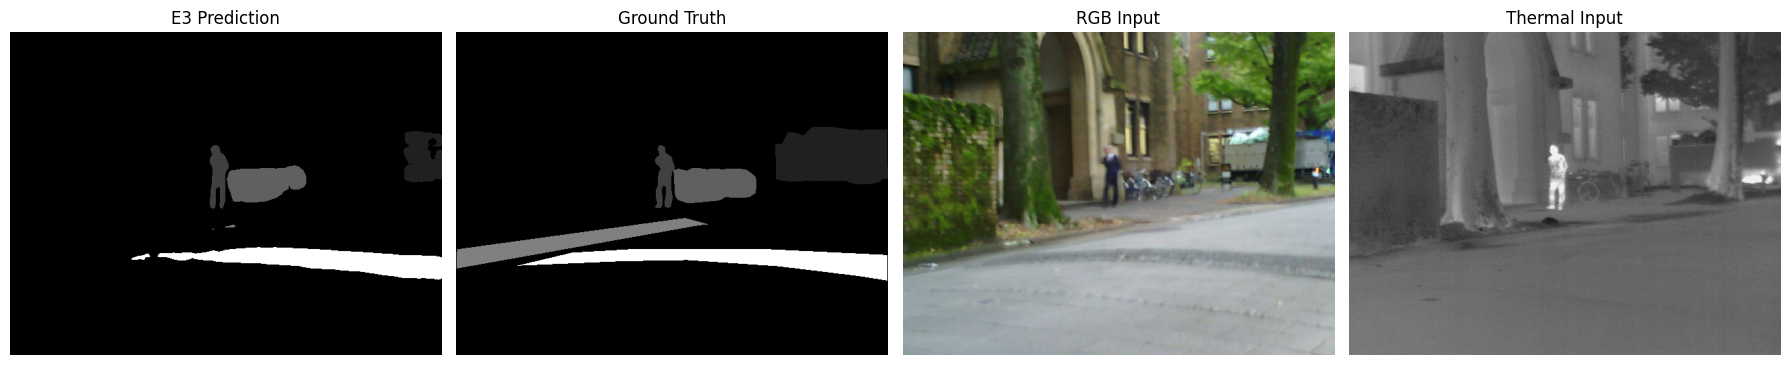

In [55]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np

image_name = "00498D.png"
stem = Path(image_name).stem

roots = [
    PROJECT / "datasets" / "TDD",
    Path("/home/cse-sdpl/Downloads/CMX_Original/datasets/TDD"),
]

pred_path = PRED_DIR / image_name
assert pred_path.exists(), f"Prediction missing: {pred_path}"

# Locate files with the same filename in the dataset.
matches = []
for root in roots:
    if root.exists():
        matches.extend(root.rglob(image_name))

def find_modality(keywords):
    candidates = [
        p for p in matches
        if any(k in str(p.parent).lower() for k in keywords)
    ]
    return candidates[0] if candidates else None

rgb_path = find_modality(["rgb", "visible"])
thermal_path = find_modality(["thermal", "infrared", "ir"])
gt_path = find_modality(["label", "mask", "annotation", "gt"])

items = [
    ("E3 Prediction", pred_path, "gray"),
    ("Ground Truth", gt_path, "gray"),
    ("RGB Input", rgb_path, None),
    ("Thermal Input", thermal_path, "gray"),
]

fig, axes = plt.subplots(1, 4, figsize=(18, 5))

for ax, (title, path, cmap) in zip(axes, items):
    ax.set_title(title)
    ax.axis("off")

    if path is None:
        ax.text(0.5, 0.5, "Image not located",
                ha="center", va="center")
        continue

    img = np.array(Image.open(path))
    ax.imshow(img, cmap=cmap, vmin=0 if cmap == "gray" else None)

plt.tight_layout()
plt.show()

In [56]:
from pathlib import Path

root = Path("/home/cse-sdpl/Downloads/CMX_E3")

print("E3 directory exists:", root.exists())

for p in root.rglob("*"):
    if p.is_file() and (
        p.suffix.lower() in {".log", ".txt"}
        or "events.out.tfevents" in p.name
    ):
        print(p)

E3 directory exists: True
/home/cse-sdpl/Downloads/CMX_E3/requirements.txt
/home/cse-sdpl/Downloads/CMX_E3/log_TDD_mit_b2_e1/val_2026_10_13_10_17_42.log
/home/cse-sdpl/Downloads/CMX_E3/log_TDD_mit_b2_e1/val_last.log
/home/cse-sdpl/Downloads/CMX_E3/log_TDD_mit_b2_e1/tb/tb/events.out.tfevents.1791826786.cse-sdpl-HP-Z4-G5-Workstation-Desktop-PC
/home/cse-sdpl/Downloads/CMX_E3/log_TDD_mit_b2_e1/tb/Oct12_12-23-09/events.out.tfevents.1791826786.cse-sdpl-HP-Z4-G5-Workstation-Desktop-PC
/home/cse-sdpl/Downloads/CMX_E3/log_TDD_mit_b2_e2/val_last.log
/home/cse-sdpl/Downloads/CMX_E3/log_TDD_mit_b2_e2/val_2026_10_13_21_27_18.log
/home/cse-sdpl/Downloads/CMX_E3/log_TDD_mit_b2_e2/tb/tb/events.out.tfevents.1791874786.cse-sdpl-HP-Z4-G5-Workstation-Desktop-PC
/home/cse-sdpl/Downloads/CMX_E3/log_TDD_mit_b2_e2/tb/Oct13_13-12-15/events.out.tfevents.1791873923.cse-sdpl-HP-Z4-G5-Workstation-Desktop-PC
/home/cse-sdpl/Downloads/CMX_E3/log_TDD_mit_b2_e2/tb/Oct13_13-12-29/events.out.tfevents.1791874786.cse-sdpl

In [57]:

from pathlib import Path

projects = {
    "E0": Path("/home/cse-sdpl/Downloads/CMX_Original"),
    "E1": Path("/home/cse-sdpl/Downloads/CMX_E1"),
    "E2": Path("/home/cse-sdpl/Downloads/CMX_E2"),
    "E3": Path("/home/cse-sdpl/Downloads/CMX_E3"),
}

for name, root in projects.items():
    print(f"\n{'='*20} {name} {'='*20}")
    print("Folder exists:", root.exists())

    if not root.exists():
        continue

    for pattern in [
        "*.log", "*.txt", "*.json", "*.tfevents*",
        "*checkpoint*.pth", "*.pth"
    ]:
        matches = list(root.rglob(pattern))
        for path in matches[:15]:
            print(path)



==================== E0 ====================
Folder exists: True
/home/cse-sdpl/Downloads/CMX_Original/log_TDD_mit_b2/val_2026_10_12_20_50_39.log
/home/cse-sdpl/Downloads/CMX_Original/log_TDD_mit_b2/val_2026_10_12_20_52_40.log
/home/cse-sdpl/Downloads/CMX_Original/log_TDD_mit_b2/val_2026_10_12_18_04_47.log
/home/cse-sdpl/Downloads/CMX_Original/log_TDD_mit_b2/val_2026_10_12_20_48_30.log
/home/cse-sdpl/Downloads/CMX_Original/log_TDD_mit_b2/val_2026_10_12_20_53_43.log
/home/cse-sdpl/Downloads/CMX_Original/log_TDD_mit_b2/val_2026_10_12_20_55_36.log
/home/cse-sdpl/Downloads/CMX_Original/log_TDD_mit_b2/val_2026_10_12_20_49_56.log
/home/cse-sdpl/Downloads/CMX_Original/log_TDD_mit_b2/val_last.log
/home/cse-sdpl/Downloads/CMX_Original/log_TDD_mit_b2/val_2026_10_12_20_51_42.log
/home/cse-sdpl/Downloads/CMX_Original/requirements.txt
/home/cse-sdpl/Downloads/CMX_Original/.venv/lib/python3.14/site-packages/easydict-1.13.dist-info/top_level.txt
/home/cse-sdpl/Downloads/CMX_Original/.venv/lib/python

In [58]:

from pathlib import Path

experiments = {
    "E0": (
        "/home/cse-sdpl/Downloads/CMX_Original",
        "log_TDD_mit_b2"
    ),
    "E1": (
        "/home/cse-sdpl/Downloads/CMX_E1",
        "log_TDD_mit_b2_e1"
    ),
    "E2": (
        "/home/cse-sdpl/Downloads/CMX_E2",
        "log_TDD_mit_b2_e2"
    ),
    "E3": (
        "/home/cse-sdpl/Downloads/CMX_E3",
        "log_TDD_mit_b2_e3"
    ),
}

for name, (base, log_name) in experiments.items():
    log_dir = Path(base) / log_name
    print(f"\n{'='*18} {name} {'='*18}")
    print("Experiment directory:", log_dir)
    print("Exists:", log_dir.exists())

    if not log_dir.exists():
        continue

    checkpoint_dir = log_dir / "checkpoint"
    if checkpoint_dir.exists():
        checkpoints = sorted(
            checkpoint_dir.glob("*.pth")
        )
        print("Checkpoints:", [p.name for p in checkpoints])

    for log_file in sorted(log_dir.glob("val*.log")):
        print(f"\n--- {log_file.name} ---")
        lines = log_file.read_text(
            errors="replace"
        ).splitlines()

        # Print the final 35 lines of each validation log
        for line in lines[-35:]:
            print(line)



================== E0 ==================
Experiment directory: /home/cse-sdpl/Downloads/CMX_Original/log_TDD_mit_b2
Exists: True
Checkpoints: ['epoch-10.pth', 'epoch-100.pth', 'epoch-15.pth', 'epoch-20.pth', 'epoch-25.pth', 'epoch-30.pth', 'epoch-35.pth', 'epoch-40.pth', 'epoch-45.pth', 'epoch-5.pth', 'epoch-50.pth', 'epoch-55.pth', 'epoch-60.pth', 'epoch-65.pth', 'epoch-70.pth', 'epoch-75.pth', 'epoch-80.pth', 'epoch-85.pth', 'epoch-90.pth', 'epoch-95.pth', 'epoch-last.pth']

--- val_2026_10_12_18_04_47.log ---
Model: /home/cse-sdpl/Downloads/CMX_Original/log_TDD_mit_b2/checkpoint/epoch-100.pth
1 unlabeled	97.775%
2 car   	87.045%
3 person	71.804%
4 bike  	72.866%
5 curve 	38.150%
6 car_stop	39.068%
7 guardrail	48.623%
8 color_cone	58.333%
9 bump  	50.866%
----------     mean_IoU	62.726%	freq_IoU	95.784%	mean_pixel_acc	72.982%	pixel_acc	97.732%

--- val_2026_10_12_20_48_30.log ---

--- val_2026_10_12_20_49_56.log ---

--- val_2026_10_12_20_50_39.log ---

--- val_2026_10_12_20_51_42.l

In [59]:
# training acc

In [61]:

%pip install tensorboard


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 283.2 kB/s  0:00:193.7 kB/s eta 0:00:01:06
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.2/7.2 MB 191.1 kB/s  0:00:37a 0:00:01m eta 0:00:02
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 222.2 kB/s  0:00:30 eta 0:00:010:02:03
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [tensorboard] 5/6 [tensorboard]rboard-data-server]
Note: you may need to restart the kernel to use updated packages.


In [62]:

from pathlib import Path

from tensorboard.backend.event_processing.event_accumulator import (
    EventAccumulator
)

experiments = {
    "E0": Path("/home/cse-sdpl/Downloads/CMX_Original/log_TDD_mit_b2"),
    "E1": Path("/home/cse-sdpl/Downloads/CMX_E1/log_TDD_mit_b2_e1"),
    "E2": Path("/home/cse-sdpl/Downloads/CMX_E2/log_TDD_mit_b2_e2"),
    "E3": Path("/home/cse-sdpl/Downloads/CMX_E3/log_TDD_mit_b2_e3"),
}

for name, log_dir in experiments.items():
    print(f"\n{'='*15} {name} {'='*15}")

    event_files = list(log_dir.rglob("events.out.tfevents.*"))
    print("Event files found:", len(event_files))

    for event_file in event_files:
        try:
            ea = EventAccumulator(str(event_file))
            ea.Reload()
            tags = ea.Tags().get("scalars", [])

            print(f"\nFile: {event_file.relative_to(log_dir)}")
            print("Scalar tags:", tags if tags else "No scalar metrics")

            for tag in tags:
                values = ea.Scalars(tag)
                if values:
                    print(
                        f"  {tag}: "
                        f"first={values[0].value:.6f}, "
                        f"last={values[-1].value:.6f}, "
                        f"steps={len(values)}"
                    )
        except Exception as e:
            print("Could not read:", e)



=============== E0 ===============
Event files found: 3

File: tb/Oct12_12-02-50/events.out.tfevents.1791753656.cse-sdpl-HP-Z4-G5-Workstation-Desktop-PC
Scalar tags: ['train_loss']
  train_loss: first=1.408638, last=0.015417, steps=100

File: tb/Oct12_12-02-48/events.out.tfevents.1791753499.cse-sdpl-HP-Z4-G5-Workstation-Desktop-PC
Scalar tags: No scalar metrics

File: tb/Oct12_12-02-49/events.out.tfevents.1791753576.cse-sdpl-HP-Z4-G5-Workstation-Desktop-PC
Scalar tags: No scalar metrics

=============== E1 ===============
Event files found: 1

File: tb/Oct12_12-23-09/events.out.tfevents.1791826786.cse-sdpl-HP-Z4-G5-Workstation-Desktop-PC
Scalar tags: ['train_loss']
  train_loss: first=1.427459, last=0.014792, steps=100

=============== E2 ===============
Event files found: 4

File: tb/Oct13_13-12-15/events.out.tfevents.1791873923.cse-sdpl-HP-Z4-G5-Workstation-Desktop-PC
Scalar tags: No scalar metrics

File: tb/Oct13_13-12-29/events.out.tfevents.1791874786.cse-sdpl-HP-Z4-G5-Workstation

In [63]:

from pathlib import Path

root = Path("/home/cse-sdpl/Downloads/CMX_Original")

for filename in ["eval.py", "dataset/TDD.py", "datasets/TDD.py"]:
    path = root / filename
    if path.exists():
        print(f"\n{'='*20}\nFILE: {path}\n")
        lines = path.read_text(errors="replace").splitlines()

        for i, line in enumerate(lines, start=1):
            if any(term in line.lower() for term in [
                "val.txt", "test.txt", "train.txt",
                "mean_iou", "pixel_acc", "confusion",
                "dataset", "split"
            ]):
                start = max(0, i - 3)
                end = min(len(lines), i + 4)
                print(f"\n--- lines {start+1}-{end} ---")
                for j in range(start, end):
                    print(f"{j+1}: {lines[j]}")



FILE: /home/cse-sdpl/Downloads/CMX_Original/eval.py


--- lines 14-20 ---
14: from engine.logger import get_logger
15: from utils.metric import hist_info, compute_score
16: from dataloader.RGBXDataset import RGBXDataset
17: from models.builder import EncoderDecoder as segmodel
18: from dataloader.dataloader import ValPre
19: 
20: logger = get_logger()

--- lines 43-49 ---
43: 
44:         if self.show_image:
45:             colors = self.dataset.get_class_colors
46:             image = img
47:             clean = np.zeros(label.shape)
48:             comp_img = show_img(colors, config.background, image, clean,
49:                                 label,

--- lines 65-71 ---
65:             count += 1
66: 
67:         iou, mean_IoU, _, freq_IoU, mean_pixel_acc, pixel_acc = compute_score(hist, correct, labeled)
68:         result_line = print_iou(iou, freq_IoU, mean_pixel_acc, pixel_acc,
69:                                 dataset.class_names, show_no_back=False)
70:         return resul

In [64]:

from pathlib import Path

root = Path("/home/cse-sdpl/Downloads/CMX_Original")

for path in root.rglob("eval.py"):
    if ".venv" not in str(path):
        print(path)


/home/cse-sdpl/Downloads/CMX_Original/eval.py


In [65]:

from pathlib import Path

path = Path("/home/cse-sdpl/Downloads/CMX_Original/eval.py")
lines = path.read_text().splitlines()

for start, end in [(70, 125), (1, 70)]:
    print(f"\n===== eval.py lines {start}-{end} =====")
    for i in range(start - 1, min(end, len(lines))):
        print(f"{i+1}: {lines[i]}")



===== eval.py lines 70-125 =====
70:         return result_line
71: 
72: if __name__ == "__main__":
73:     parser = argparse.ArgumentParser()
74:     parser.add_argument('-e', '--epochs', default='last', type=str)
75:     parser.add_argument('-d', '--devices', default='0', type=str)
76:     parser.add_argument('-v', '--verbose', default=False, action='store_true')
77:     parser.add_argument('--show_image', '-s', default=False,
78:                         action='store_true')
79:     parser.add_argument('--save_path', '-p', default=None)
80: 
81:     args = parser.parse_args()
82:     all_dev = parse_devices(args.devices)
83: 
84:     network = segmodel(cfg=config, criterion=None, norm_layer=nn.BatchNorm2d)
85:     data_setting = {'rgb_root': config.rgb_root_folder,
86:                     'rgb_format': config.rgb_format,
87:                     'gt_root': config.gt_root_folder,
88:                     'gt_format': config.gt_format,
89:                     'transform_gt': config.gt_t